# Africa-USA Skilled Worker Visa Flows - Exploratory Data Analysis

**Domain:** Global Immigration | **Focus:** 10 African source countries and the United States | **Period:** 2011-2025

The United States is a leading destination for degree-holding African professionals - engineers, physicians,
nurses and software developers - many of whom enter through employment-based channels such as the **H-1B**
specialty-occupation visa. Country-level H-1B and green-card counts are published by USCIS
([H-1B Employer Data Hub](https://www.uscis.gov/tools/reports-and-studies/h-1b-employer-data-hub)) and DHS
([Yearbook of Immigration Statistics](https://www.dhs.gov/immigration-statistics/yearbook)); this notebook studies the
**source-country side** of that pipeline with World Bank indicators:

| Question | Indicator(s) |
|---|---|
| Who is losing people on net? | Net migration (`SM.POP.NETM`), population |
| How much does the diaspora send home? | Personal remittances, US$ and % of GDP |
| Is emigration linked to income? | GDP per capita |
| Is there an educated pool at risk of brain drain? | Tertiary enrollment (% gross) |
| How does Africa compare with US absorption? | USA net migration |

Data is read from `data/migration_analytics.db`, produced by the pipeline
(`ingest.py` -> `transform.py` -> `load.py`).

In [1]:
import sqlite3
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pio.renderers.default = "plotly_mimetype+notebook_connected"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Works whether the notebook is launched from the project root or notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DB_PATH = PROJECT_ROOT / "data" / "migration_analytics.db"
assert DB_PATH.exists(), f"{DB_PATH} not found - run the pipeline first (see README)"

with sqlite3.connect(DB_PATH) as conn:
    countries = pd.read_sql("SELECT * FROM countries", conn)
    panel = pd.read_sql(
        "SELECT m.*, c.country_name, c.subregion FROM migration_indicators m "
        "JOIN countries c USING (iso3) ORDER BY c.country_name, m.year", conn)
    yearly = pd.read_sql("SELECT * FROM yearly_summary ORDER BY year", conn)

COUNTRY_ORDER = countries.sort_values("country_name")["country_name"].tolist()
PALETTE = dict(zip(COUNTRY_ORDER, sns.color_palette("tab10", len(COUNTRY_ORDER))))
print(f"countries: {countries.shape}, migration_indicators: {panel.shape}, yearly_summary: {yearly.shape}")
print(f"Years covered: {panel.year.min()}-{panel.year.max()}")

countries: (10, 17), migration_indicators: (150, 20), yearly_summary: (15, 14)
Years covered: 2011-2025


## 1. Data overview and quality

In [2]:
display(panel[["country_name", "year", "net_migration", "remittances_usd", "remittances_pct_gdp",
               "gdp_per_capita", "tertiary_enrollment", "population"]].head(8))

core = ["net_migration", "remittances_usd", "remittances_pct_gdp", "gdp_per_capita",
        "tertiary_enrollment", "population"]
quality = pd.DataFrame({
    "non_null": panel[core].notna().sum(),
    "missing": panel[core].isna().sum(),
    "missing_pct": (panel[core].isna().mean() * 100).round(1),
})
quality.loc["tertiary_enrollment", "imputed (ffill/bfill/interp)"] = int(panel["tertiary_enrollment_imputed"].sum())
display(quality)
display(panel[core + ["net_migration_rate_per_1000", "remittances_per_capita",
                      "migration_intensity_index", "skilled_worker_proxy_score"]].describe().T.round(2))

,country_name,year,net_migration,remittances_usd,remittances_pct_gdp,gdp_per_capita,tertiary_enrollment,population
0,Egypt,2011,126170.0,1.432430e+10,6.069884,2590.643849,25.590182,91093059.0
1,Egypt,2012,-2626.0,1.923640e+10,6.891885,2996.067707,26.227157,93161001.0
2,Egypt,2013,130305.0,1.783310e+10,6.182729,3025.525636,28.347982,95333553.0
3,Egypt,2014,-92801.0,1.957040e+10,6.404023,3133.391023,29.113433,97528654.0
4,Egypt,2015,-193298.0,1.832540e+10,5.563831,3306.981594,32.884899,99597342.0
5,Egypt,2016,-71604.0,1.859040e+10,5.592078,3270.628777,31.873131,101644589.0
6,Egypt,2017,-80000.0,2.473740e+10,9.960188,2395.103333,33.101889,103696057.0
7,Egypt,2018,20788.0,2.551570e+10,9.716986,2484.703156,36.123001,105682094.0


,non_null,missing,missing_pct,imputed (ffill/bfill/interp)
net_migration,150,0,0.0,NaN
remittances_usd,146,4,2.7,NaN
remittances_pct_gdp,146,4,2.7,NaN
gdp_per_capita,150,0,0.0,NaN
tertiary_enrollment,150,0,0.0,56.0
population,150,0,0.0,NaN


,count,mean,std,min,25%,50%,75%,max
net_migration,150.0,1.160122e+04,1.411283e+05,-8.792350e+05,-5.472100e+04,-1.055700e+04,4.264825e+04,6.411500e+05
remittances_usd,146.0,6.709728e+09,8.840534e+09,3.261607e+08,9.272490e+08,2.131362e+09,7.374682e+09,4.151740e+10
remittances_pct_gdp,146.0,4.180000e+00,3.160000e+00,2.100000e-01,1.470000e+00,3.600000e+00,6.080000e+00,1.137000e+01
gdp_per_capita,150.0,2.386500e+03,1.749870e+03,3.430200e+02,1.087160e+03,1.935130e+03,3.144900e+03,8.646060e+03
tertiary_enrollment,150.0,1.536000e+01,1.135000e+01,2.860000e+00,5.920000e+00,1.071000e+01,2.133000e+01,4.818000e+01
population,150.0,7.139795e+07,5.413832e+07,1.295890e+07,3.513246e+07,5.260627e+07,9.930769e+07,2.375278e+08
net_migration_rate_per_1000,150.0,9.000000e-02,2.580000e+00,-1.536000e+01,-9.900000e-01,-1.700000e-01,1.010000e+00,1.130000e+01
remittances_per_capita,146.0,9.332000e+01,8.818000e+01,3.400000e+00,1.676000e+01,7.122000e+01,1.491200e+02,3.553600e+02
migration_intensity_index,146.0,3.333000e+01,1.863000e+01,8.700000e-01,1.866000e+01,3.072000e+01,4.861000e+01,7.584000e+01
skilled_worker_proxy_score,146.0,3.030000e+01,2.370000e+01,2.300000e-01,1.730000e+01,2.357000e+01,3.735000e+01,9.106000e+01


**Quality notes.** Net migration, GDP per capita and population are complete for all 150 country-years.
Remittances are missing for the most recent year(s) of a few countries (latest data not yet published), so
2024-2025 regional totals cover fewer than 10 countries. Tertiary enrollment is the sparsest indicator
(UNESCO reports irregularly): gaps were interpolated within a country and edge years carried forward/back,
and every imputed value is flagged in `tertiary_enrollment_imputed`.

## 2. Who is losing people? Net migration by country

World Bank net migration is *immigrants minus emigrants*; negative values mean a country is a net sender.
Raw counts favour populous countries, so we also show the rate per 1,000 residents.

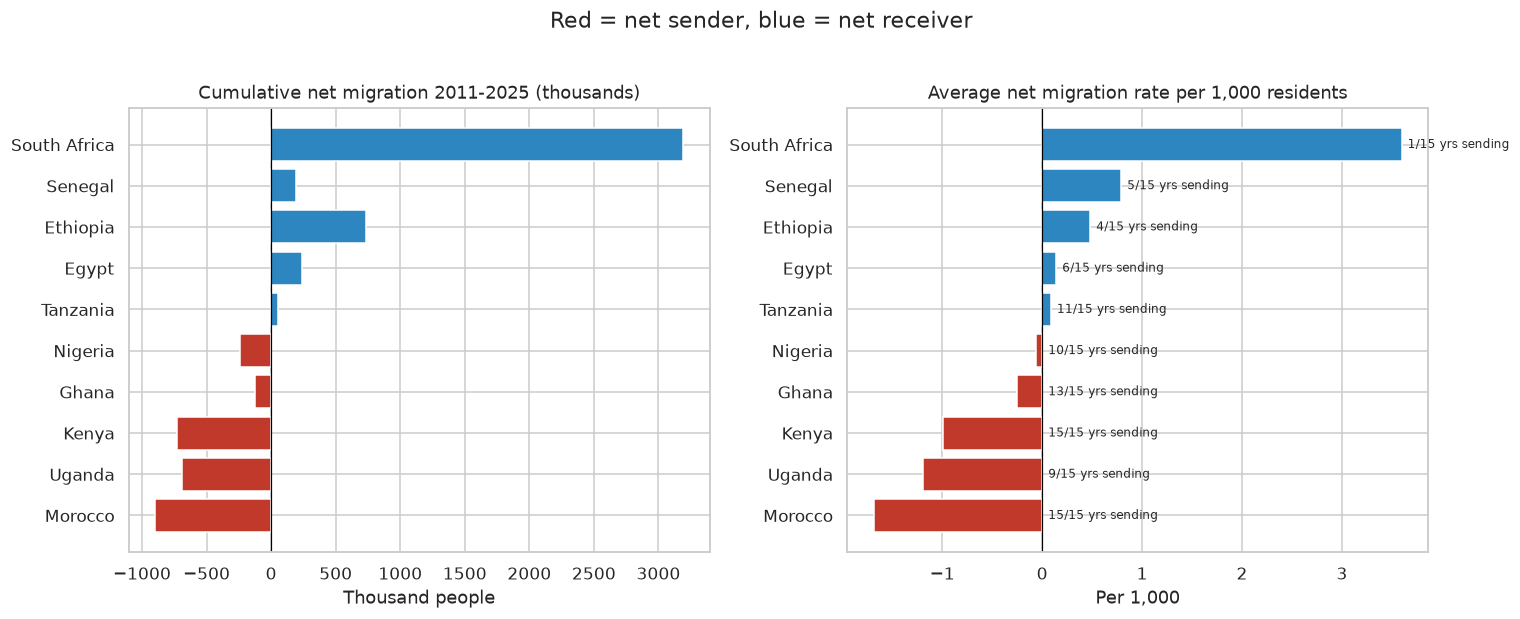

,total_net_migration,avg_rate_per_1000,net_emigration_years
country_name,,,
Morocco,-896933.0,-1.686,15
Uganda,-691046.0,-1.194,9
Kenya,-726344.0,-0.996,15
Ghana,-122595.0,-0.256,13
Nigeria,-239416.0,-0.062,10
Tanzania,53691.0,0.087,11
Egypt,241453.0,0.139,6
Ethiopia,736876.0,0.481,4
Senegal,192873.0,0.790,5


In [3]:
by_country = (panel.groupby("country_name")
              .agg(total_net_migration=("net_migration", "sum"),
                   avg_rate_per_1000=("net_migration_rate_per_1000", "mean"),
                   net_emigration_years=("is_net_emigration", "sum"))
              .sort_values("avg_rate_per_1000"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colors = ["#c0392b" if v < 0 else "#2e86c1" for v in by_country["total_net_migration"]]
axes[0].barh(by_country.index, by_country["total_net_migration"] / 1e3, color=colors)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set(title="Cumulative net migration 2011-2025 (thousands)", xlabel="Thousand people")

colors = ["#c0392b" if v < 0 else "#2e86c1" for v in by_country["avg_rate_per_1000"]]
axes[1].barh(by_country.index, by_country["avg_rate_per_1000"], color=colors)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set(title="Average net migration rate per 1,000 residents", xlabel="Per 1,000")
for i, (rate, yrs) in enumerate(zip(by_country["avg_rate_per_1000"], by_country["net_emigration_years"])):
    axes[1].annotate(f"{int(yrs)}/15 yrs sending", (max(rate, 0), i), xytext=(4, 0),
                     textcoords="offset points", va="center", ha="left", fontsize=8)
fig.suptitle("Red = net sender, blue = net receiver", y=1.02)
plt.tight_layout()
plt.show()
display(by_country.round(3))

**Reading the chart.** Morocco and Kenya were net senders in all 15 years, and Uganda and Morocco have the
deepest population-adjusted outflows. South Africa is the clear outlier - a *regional magnet* that absorbs
migrants from the rest of the continent even while its own professionals emigrate - so continent-wide totals
can mask very large sending flows from individual countries.

## 3. Remittance flows - the financial return of the diaspora

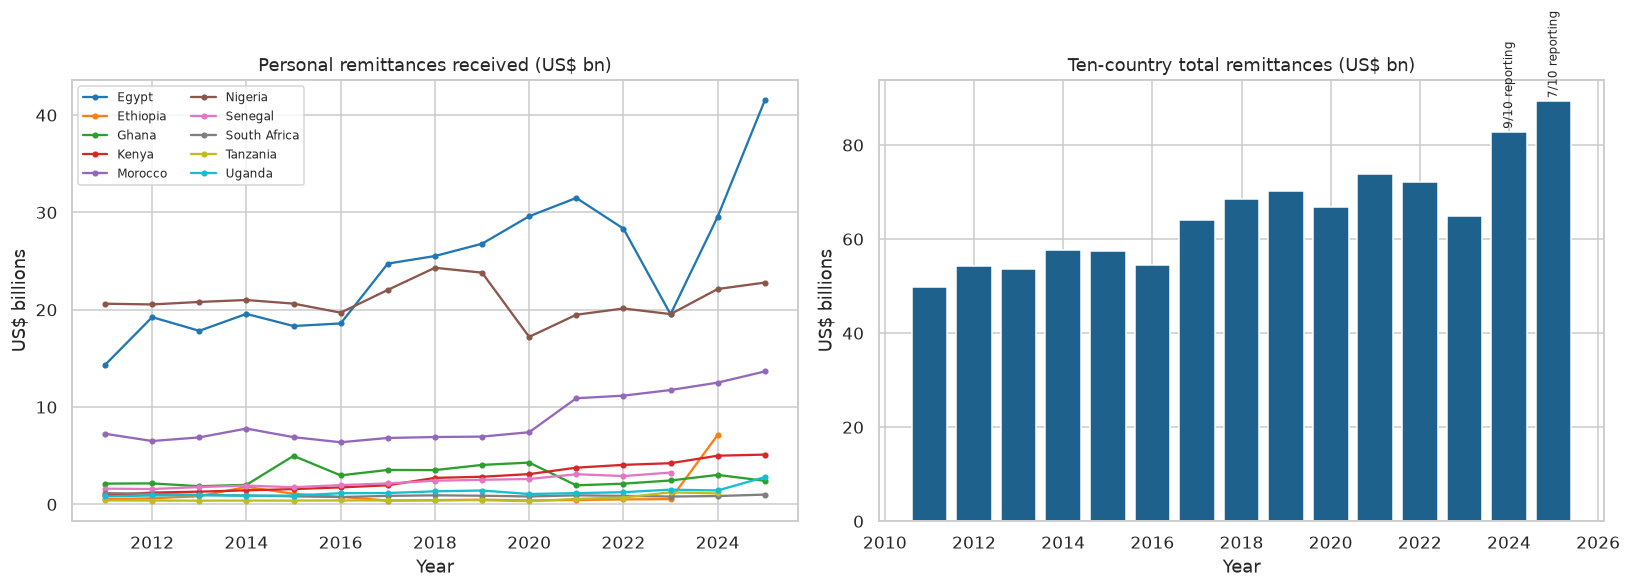

2011 total: $49.8bn  |  2024 total (9 of 10 reporting): $82.8bn


,country_name,remittances_cagr_pct,avg_remittances_pct_gdp,cumulative_remittances_bn
1,Egypt,7.90,7.32,364.9
7,Nigeria,0.72,4.74,314.7
0,Morocco,4.62,6.62,129.8
3,Ghana,0.91,4.66,43.5
4,Kenya,12.91,2.87,41.0
2,Senegal,6.04,10.15,29.6
6,Uganda,9.20,3.30,18.7
9,Ethiopia,22.00,1.35,16.0
5,South Africa,-1.01,0.23,13.7
8,Tanzania,8.07,0.91,7.6


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for name, grp in panel.groupby("country_name"):
    axes[0].plot(grp["year"], grp["remittances_usd"] / 1e9, marker="o", ms=3, label=name, color=PALETTE[name])
axes[0].set(title="Personal remittances received (US$ bn)", xlabel="Year", ylabel="US$ billions")
axes[0].legend(fontsize=8, ncol=2)

axes[1].bar(yearly["year"], yearly["total_remittances_usd"] / 1e9, color="#1f618d")
reporting = panel.groupby("year")["remittances_usd"].count()
for year, total in zip(yearly["year"], yearly["total_remittances_usd"] / 1e9):
    if reporting[year] < 10:
        axes[1].annotate(f"{reporting[year]}/10 reporting", (year, total), xytext=(0, 4),
                         textcoords="offset points", ha="center", fontsize=8, rotation=90)
axes[1].set(title="Ten-country total remittances (US$ bn)", xlabel="Year", ylabel="US$ billions")
plt.tight_layout()
plt.show()

full = yearly.set_index("year")["total_remittances_usd"]
print(f"2011 total: ${full.loc[2011] / 1e9:.1f}bn  |  2024 total (9 of 10 reporting): ${full.loc[2024] / 1e9:.1f}bn")
display(countries[["country_name", "cumulative_remittances_usd", "remittances_cagr_pct", "avg_remittances_pct_gdp"]]
        .assign(cumulative_remittances_bn=lambda d: (d.cumulative_remittances_usd / 1e9).round(1))
        .drop(columns="cumulative_remittances_usd")
        .sort_values("cumulative_remittances_bn", ascending=False).round(2))

**Remittances keep growing.** Egypt and Nigeria together account for 60-73% of all inflows in every year; Egypt
reached a record US$41.5bn in 2025 (11.4% of GDP). Kenya and Ethiopia show the fastest compound growth,
consistent with a rapidly expanding professional diaspora in the US, the Gulf and Europe. Dips (Nigeria
2020, Egypt 2023) line up with COVID-19 and periods of exchange-rate stress, when transfers shift to informal channels.

## 4. Remittance dependence - % of GDP over time

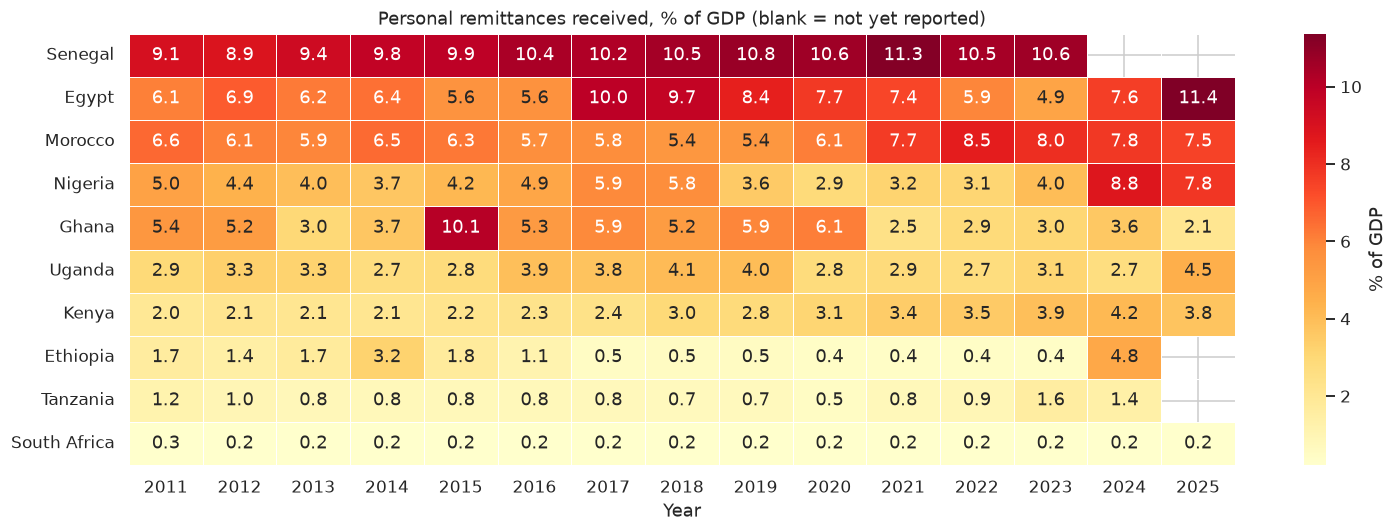

In [5]:
dep = panel.pivot(index="country_name", columns="year", values="remittances_pct_gdp")
dep = dep.loc[dep.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(dep, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.4, cbar_kws={"label": "% of GDP"}, ax=ax)
ax.set(title="Personal remittances received, % of GDP (blank = not yet reported)", xlabel="Year", ylabel="")
plt.tight_layout()
plt.show()

Senegal, Egypt and Morocco are the most remittance-dependent economies (6-11% of GDP), meaning diaspora
earnings rival or exceed foreign direct investment. South Africa and Tanzania depend least on remittances.

## 5. Does income drive migration? GDP per capita vs net migration rate

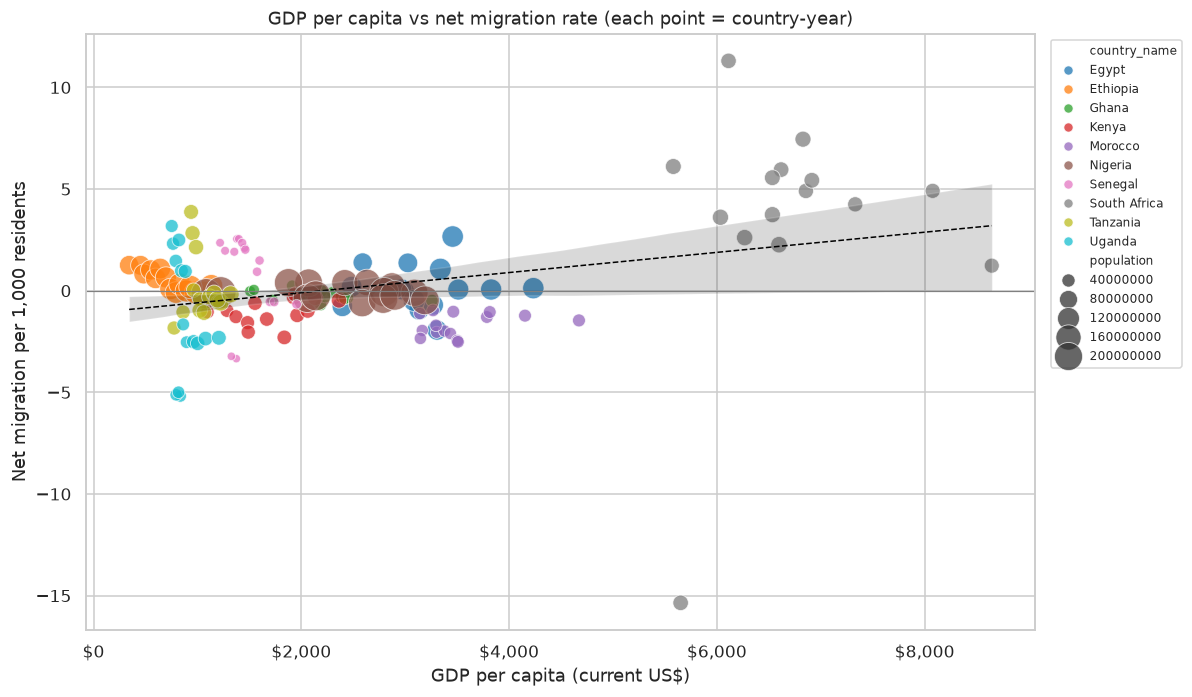

Pooled Pearson r = 0.336; excluding South Africa r = -0.178


,within-country r
country_name,
Ethiopia,-0.850
Ghana,-0.450
Uganda,-0.320
Senegal,-0.260
Nigeria,-0.173
Tanzania,-0.139
Egypt,0.040
South Africa,0.169
Morocco,0.286


In [6]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.scatterplot(data=panel, x="gdp_per_capita", y="net_migration_rate_per_1000", hue="country_name",
                hue_order=COUNTRY_ORDER, palette=PALETTE, size="population", sizes=(30, 400), alpha=0.75, ax=ax)
sns.regplot(data=panel, x="gdp_per_capita", y="net_migration_rate_per_1000", scatter=False,
            color="black", line_kws={"ls": "--", "lw": 1}, ax=ax)
ax.axhline(0, color="grey", lw=0.8)
ax.set(title="GDP per capita vs net migration rate (each point = country-year)",
       xlabel="GDP per capita (current US$)", ylabel="Net migration per 1,000 residents")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

pooled = panel[["gdp_per_capita", "net_migration_rate_per_1000"]].corr().iloc[0, 1]
excl_zaf = panel.loc[panel.iso3 != "ZAF", ["gdp_per_capita", "net_migration_rate_per_1000"]].corr().iloc[0, 1]
within = panel.groupby("country_name").apply(
    lambda g: g["gdp_per_capita"].corr(g["net_migration_rate_per_1000"])).sort_values()
print(f"Pooled Pearson r = {pooled:.3f}; excluding South Africa r = {excl_zaf:.3f}")
display(within.round(3).rename("within-country r").to_frame())

**Income alone does not explain emigration.** The pooled positive correlation is driven largely by South
Africa (highest income *and* highest net inflow); excluding it the relationship weakens sharply, and
within-country correlations point in both directions. This matches the *migration hump* hypothesis:
emigration often **rises** as incomes move from low to middle levels because more people can afford to move
and acquire the credentials that US employers sponsor - Morocco and Kenya are middle-income net senders.

## 6. Education and brain drain - tertiary enrollment vs emigration

In [7]:
agg = (panel.groupby(["country_name", "subregion"])
       .agg(tertiary_enrollment=("tertiary_enrollment", "mean"),
            emigration_rate_per_1000=("emigration_rate_per_1000", "mean"),
            net_migration_rate_per_1000=("net_migration_rate_per_1000", "mean"),
            remittances_bn=("remittances_usd", lambda s: s.sum() / 1e9),
            skilled_worker_proxy_score=("skilled_worker_proxy_score", "mean"))
       .reset_index())
fig = px.scatter(
    agg, x="tertiary_enrollment", y="net_migration_rate_per_1000", size="remittances_bn",
    color="subregion", text="country_name", size_max=55,
    hover_data={"emigration_rate_per_1000": ":.2f", "skilled_worker_proxy_score": ":.1f", "remittances_bn": ":.1f"},
    labels={"tertiary_enrollment": "Avg tertiary enrollment (% gross)",
            "net_migration_rate_per_1000": "Avg net migration per 1,000",
            "remittances_bn": "Cumulative remittances (US$ bn)"},
    title="Brain-drain exposure: education vs net migration (bubble = cumulative remittances 2011-2025)")
fig.add_hline(y=0, line_dash="dash", line_color="grey")
fig.add_vline(x=20, line_dash="dot", line_color="grey", annotation_text="20% enrollment")
fig.update_traces(textposition="top center")
fig.update_layout(height=560)
fig.show()
display(agg.sort_values("tertiary_enrollment", ascending=False).round(2))

,country_name,subregion,tertiary_enrollment,emigration_rate_per_1000,net_migration_rate_per_1000,remittances_bn,skilled_worker_proxy_score
4,Morocco,North Africa,34.78,1.69,-1.69,129.83,77.77
0,Egypt,North Africa,33.38,0.33,0.14,364.95,63.22
7,South Africa,Southern Africa,21.05,1.02,3.60,13.67,23.26
2,Ghana,West Africa,17.00,0.27,-0.26,43.52,28.89
6,Senegal,West Africa,12.69,0.56,0.79,29.62,30.96
3,Kenya,East Africa,9.98,1.00,-1.00,41.00,24.29
5,Nigeria,West Africa,9.74,0.18,-0.06,314.72,20.21
1,Ethiopia,East Africa,6.18,0.02,0.48,16.00,3.46
9,Uganda,East Africa,4.52,1.95,-1.19,18.74,20.40
8,Tanzania,East Africa,4.29,0.50,0.09,7.56,7.28


**The brain-drain quadrant** (high enrollment, negative net migration) is occupied by **Morocco**: over a
third of young adults enroll in tertiary education while the country loses ~1.2-1.7 residents per 1,000 every
year. Egypt has similar enrollment but a positive average balance (it hosts large refugee populations that
offset professional emigration). Kenya, Ghana, Uganda and Nigeria combine lower enrollment with persistent net
outflows - their emigrants are fewer in relative terms, but those with degrees are disproportionately likely
to leave, consistent with Migration Policy Institute findings that Nigerian-born immigrants are among the most highly
educated immigrant groups in the US.

## 7. Correlation matrix of indicators and derived metrics

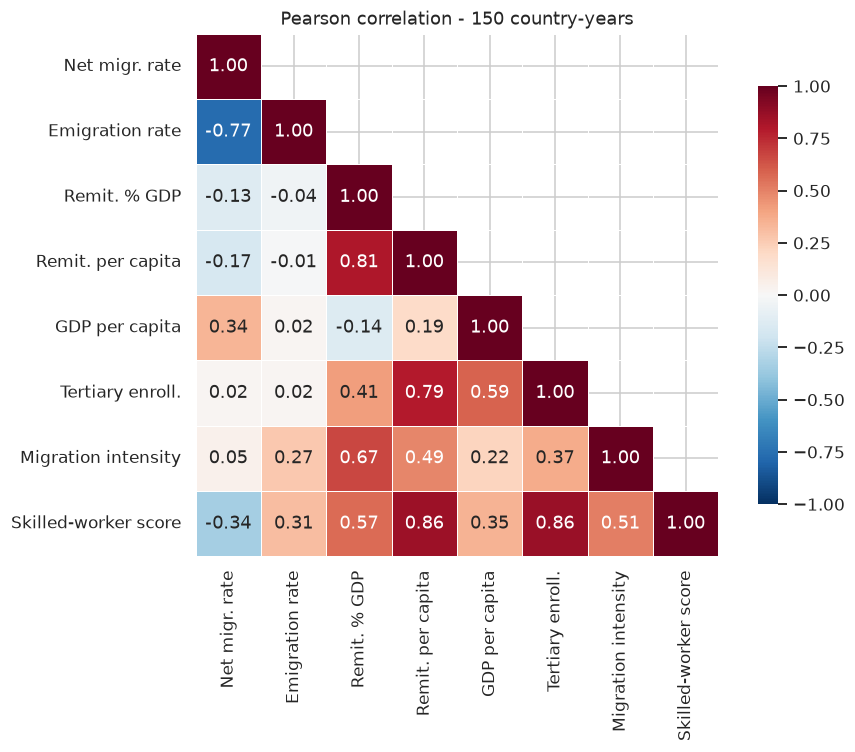

In [8]:
corr_cols = {
    "net_migration_rate_per_1000": "Net migr. rate",
    "emigration_rate_per_1000": "Emigration rate",
    "remittances_pct_gdp": "Remit. % GDP",
    "remittances_per_capita": "Remit. per capita",
    "gdp_per_capita": "GDP per capita",
    "tertiary_enrollment": "Tertiary enroll.",
    "migration_intensity_index": "Migration intensity",
    "skilled_worker_proxy_score": "Skilled-worker score",
}
corr = panel[list(corr_cols)].rename(columns=corr_cols).corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation - 150 country-years")
plt.tight_layout()
plt.show()

Tertiary enrollment correlates moderately with GDP per capita (r ~ 0.6) and strongly with remittances per
capita (r ~ 0.8): more educated,
richer source countries receive more money per resident from their diaspora - a signature of skilled
emigrants earning destination-country professional salaries.

## 8. Net migration rate heatmap - country x year

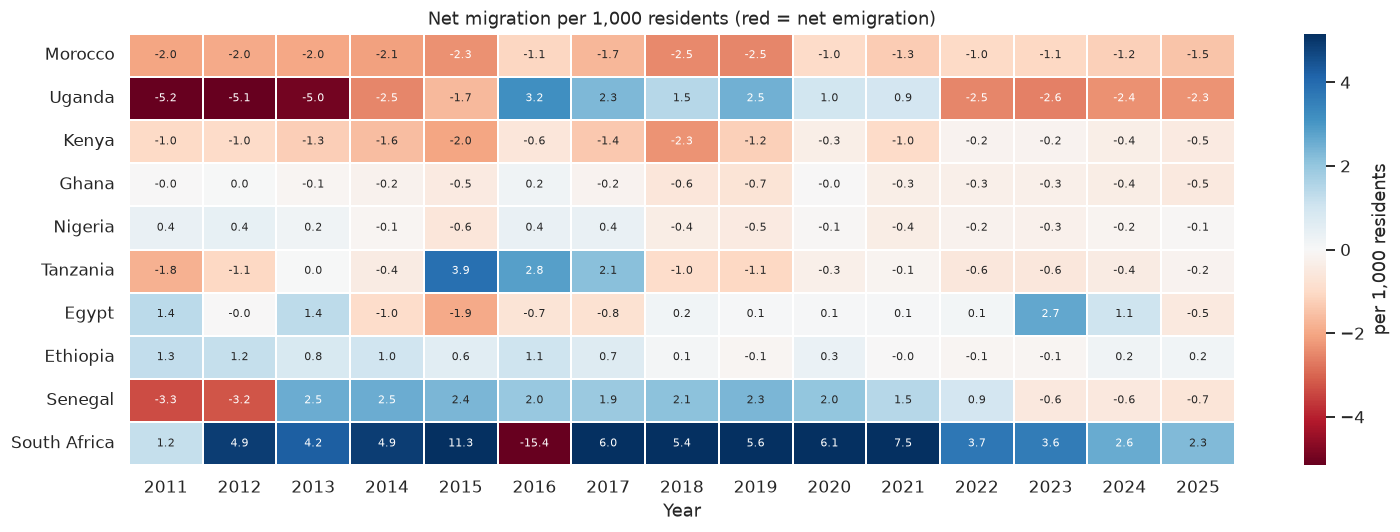

In [9]:
rates = panel.pivot(index="country_name", columns="year", values="net_migration_rate_per_1000")
rates = rates.loc[rates.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(14, 5))
lim = np.nanpercentile(np.abs(rates.values), 95)
sns.heatmap(rates, cmap="RdBu", center=0, vmin=-lim, vmax=lim, annot=True, fmt=".1f",
            annot_kws={"fontsize": 7}, linewidths=0.3, cbar_kws={"label": "per 1,000 residents"}, ax=ax)
ax.set(title="Net migration per 1,000 residents (red = net emigration)", xlabel="Year", ylabel="")
plt.tight_layout()
plt.show()

## 9. Skilled-worker proxy score - which countries feed skilled visa channels?

`skilled_worker_proxy_score` (0-100) blends tertiary enrollment (40%), remittances per capita (30%) and
emigration rate (30%), each winsorised at the 5th/95th percentile and min-max normalised over the panel. It is a **proxy** for the size of the educated,
mobile population that typically competes for H-1B and other employment-based visas - not a visa count.

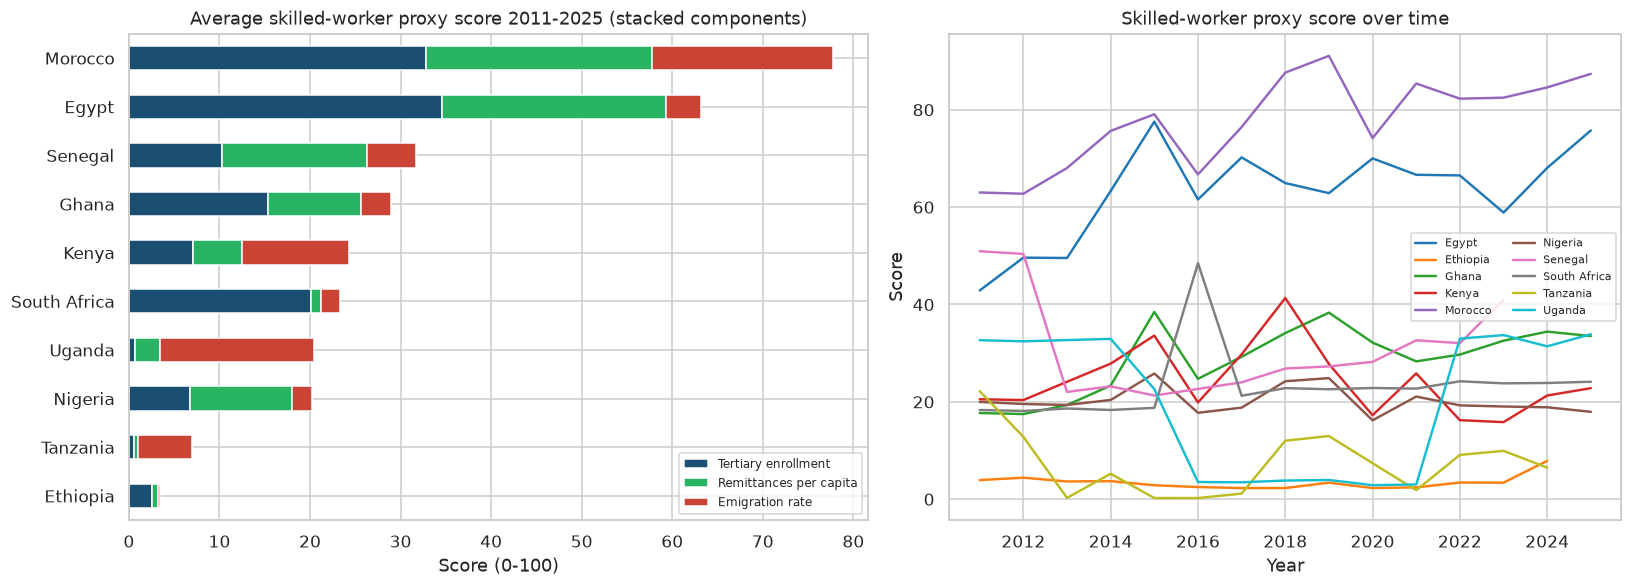

,skilled_worker_rank,country_name,avg_skilled_worker_proxy_score,avg_migration_intensity_index,avg_tertiary_enrollment,avg_net_migration_rate_per_1000
0,1,Morocco,77.77,47.49,34.78,-1.69
1,2,Egypt,63.22,41.82,33.38,0.14
2,3,Senegal,30.96,68.18,12.69,0.79
3,4,Ghana,28.89,24.23,17.00,-0.26
4,5,Kenya,24.29,22.19,9.98,-1.00
5,6,South Africa,23.26,41.03,21.05,3.60
6,7,Uganda,20.40,41.12,4.52,-1.19
7,8,Nigeria,20.21,24.62,9.74,-0.06
8,9,Tanzania,7.28,14.18,4.29,0.09
9,10,Ethiopia,3.46,10.31,6.18,0.48


In [10]:
weights = {"tertiary_enrollment_norm": 0.4, "remittances_per_capita_norm": 0.3, "emigration_rate_per_1000_norm": 0.3}
norms = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "africa_migration_processed.csv")
comp = (norms.groupby("country")[list(weights)].mean() * pd.Series(weights) * 100)
comp.columns = ["Tertiary enrollment", "Remittances per capita", "Emigration rate"]
comp = comp.loc[comp.sum(axis=1).sort_values().index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
comp.plot.barh(stacked=True, ax=axes[0], color=["#1b4f72", "#28b463", "#cb4335"])
axes[0].set(title="Average skilled-worker proxy score 2011-2025 (stacked components)", xlabel="Score (0-100)", ylabel="")
axes[0].legend(fontsize=8, loc="lower right")

for name, grp in panel.groupby("country_name"):
    axes[1].plot(grp["year"], grp["skilled_worker_proxy_score"], label=name, color=PALETTE[name], lw=1.6)
axes[1].set(title="Skilled-worker proxy score over time", xlabel="Year", ylabel="Score")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()
display(countries.sort_values("skilled_worker_rank")[
    ["skilled_worker_rank", "country_name", "avg_skilled_worker_proxy_score", "avg_migration_intensity_index",
     "avg_tertiary_enrollment", "avg_net_migration_rate_per_1000"]].round(2))

## 10. The destination side - USA net migration vs African outflows

`gross_africa_outflow` sums the absolute net migration of the countries that were net senders in a given year.
The World Bank series has no destination breakdown, so the ratio below compares *scale*, not the share of
emigrants who went to the US.

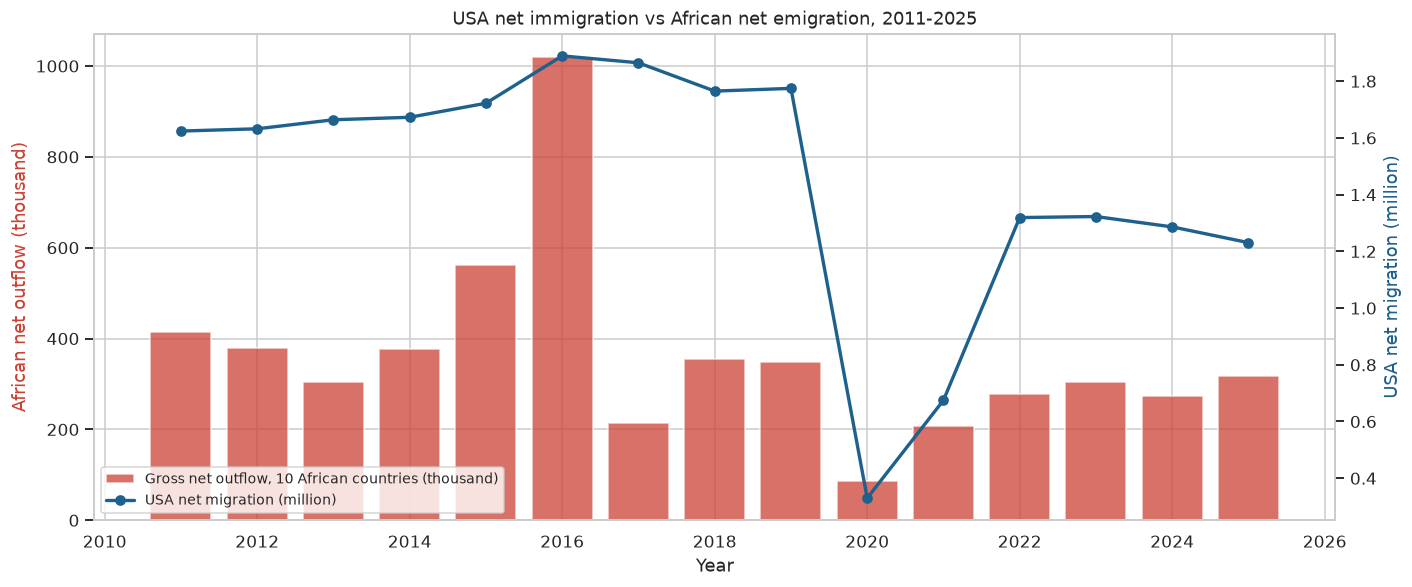

,year,net_emigration_countries,gross_africa_outflow,usa_net_migration,africa_outflow_vs_usa_inflow_pct
0,2011,6,413863.0,1624033.0,25.5
1,2012,6,379594.0,1632007.0,23.3
2,2013,4,303686.0,1663885.0,18.3
3,2014,7,376325.0,1672598.0,22.5
4,2015,6,562357.0,1722127.0,32.7
5,2016,4,1019869.0,1889129.0,54.0
6,2017,4,214087.0,1864738.0,11.5
7,2018,5,354979.0,1764961.0,20.1
8,2019,6,349154.0,1774500.0,19.7
9,2020,5,85960.0,329769.0,26.1


In [11]:
fig, ax1 = plt.subplots(figsize=(13, 5.5))
ax1.bar(yearly["year"], yearly["gross_africa_outflow"] / 1e3, color="#cb4335", alpha=0.75,
        label="Gross net outflow, 10 African countries (thousand)")
ax1.set_ylabel("African net outflow (thousand)", color="#cb4335")
ax2 = ax1.twinx()
ax2.plot(yearly["year"], yearly["usa_net_migration"] / 1e6, color="#1f618d", marker="o", lw=2.2,
         label="USA net migration (million)")
ax2.set_ylabel("USA net migration (million)", color="#1f618d")
ax2.grid(False)
ax1.set(title="USA net immigration vs African net emigration, 2011-2025", xlabel="Year")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()
display(yearly[["year", "net_emigration_countries", "gross_africa_outflow", "usa_net_migration",
                "africa_outflow_vs_usa_inflow_pct"]].round(1))

US net migration collapsed from ~1.8 million to about 330,000 in 2020 as consulates closed and travel bans
took effect, then recovered to ~1.2-1.3 million. Meanwhile the number of the ten African countries that were
net senders rose from 4-6 in the late 2010s to 7-8 in 2022-2025, and combined remittances hit new highs - the
supply of mobile, educated Africans is growing faster than US absorption has recovered.

## 11. Key findings

1. **Persistent senders.** Morocco and Kenya were net emigration countries in every year from 2011-2025;
   Uganda and Morocco have the highest population-adjusted outflows. Nigeria is a net sender in 10 of 15 years.
2. **Remittances are a macro-economic pillar.** Ten-country remittances rose from about US$50bn (2011) to
   about US$83bn (2024, 9 of 10 countries reporting). Egypt alone received US$41.5bn in 2025 (11.4% of GDP);
   Senegal relies on remittances for ~10% of GDP.
3. **Brain-drain exposure is highest where education is high and net migration negative** - Morocco is the clearest
   case and tops the skilled-worker proxy ranking, followed by Egypt, Senegal, Ghana and Kenya.
4. **The migration hump.** Income and emigration are not inversely related: middle-income countries (Morocco,
   Kenya, Ghana, Nigeria) send more than the poorest ones (Ethiopia, Tanzania), consistent with skilled migration
   requiring resources and credentials.
5. **South Africa is a dual-role country** - a large net receiver from the region while losing professionals,
   so country-level net figures understate skilled outflows.
6. **US capacity is the binding constraint.** US net migration has not returned to its 2016 peak while African
   sending pressure keeps rising - pointing to growing competition for H-1B lottery slots and employment-based
   green cards (see the USCIS and DHS sources to validate with actual visa counts).

**Limitations.** Net migration is a residual estimate with no destination breakdown; tertiary enrollment is
partially imputed; the skilled-worker proxy score is a relative index, not a visa count. Joining USCIS H-1B
approvals by country of birth would turn the proxy into a direct measure.